In [ ]:
# COLAB ONLY

# Install Kaggle from PyPI
!pip install -q kaggle
 
# Kaggle: auth
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!ls ~/.kaggle
!chmod 600 /root/.kaggle/kaggle.json
 
# Download dataset
!kaggle datasets download -d crawford/emnist
 
# Dataset: extract balanced only
!unzip emnist.zip emnist-bymerge-test.csv
!unzip emnist.zip emnist-bymerge-train.csv
!unzip emnist.zip emnist-bymerge-mapping.txt

# Nhan dang ky tu viet tay voi MLP va CNN tren tap EMNIST ByMerge

## 1. Mo ta bai toan

**Bai toan:** Phan loai anh ky tu viet tay thanh 47 lop (10 chu so 0-9, 26 chu cai in hoa A-Z, va 11 chu cai thuong co hinh dang khac biet ro ret voi dang in hoa tuong ung).

**Muc tieu:**
- Xay dung mo hinh co so (baseline) bang **Multi-layer Perceptron (MLP)**.
- Xay dung mo hinh cai tien bang **Convolutional Neural Network (CNN)**.
- So sanh hieu nang hai mo hinh tren cung tap du lieu, phan tich loi va neu han che.

## 2. Gioi thieu bo du lieu

- **Nguon:** [EMNIST ByMerge](https://www.kaggle.com/crawford/emnist) - ban mo rong cua MNIST cho ky tu viet tay.
- **So mau:** 697.932 (train) + 116.323 (test) = 814.255 mau.
- **Dac trung:** Moi mau la anh grayscale 28x28 pixel (= 784 chieu), gia tri pixel trong khoang [0, 255].
- **Nhan:** 47 lop - chi so 0-9 la chu so, 10-35 la A-Z, 36-46 la 11 chu thuong co hinh dang khac biet ro voi dang in hoa (a, b, d, e, f, g, h, n, q, r, t).
- **Dinh dang:** CSV - cot dau la nhan, 784 cot sau la pixel.

In [2]:
import numpy
import pandas
import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
train_set = pandas.read_csv('emnist-bymerge-train.csv')
test_set = pandas.read_csv('emnist-bymerge-test.csv')

In [4]:
train_set = train_set.iloc[numpy.random.permutation(len(train_set))]
test_set = test_set.iloc[numpy.random.permutation(len(test_set))]

In [5]:
train_label = numpy.array(train_set.iloc[:,0].values)
train_data = numpy.array(train_set.iloc[:,1:].values)

test_label = numpy.array(test_set.iloc[:,0].values)
test_data = numpy.array(test_set.iloc[:,1:].values)

In [6]:
label = {
    0: '0',
    1: '1',
    2: '2',
    3: '3',
    4: '4',
    5: '5',
    6: '6', 
    7: '7',
    8: '8', 
    9: '9',
    10: 'A',
    11: 'B',
    12: 'C',
    13: 'D',
    14: 'E',
    15: 'F',
    16: 'G',
    17: 'H',
    18: 'I',
    19: 'J',
    20: 'K',
    21: 'L',
    22: 'M',
    23: 'N',
    24: 'O',
    25: 'P',
    26: 'Q',
    27: 'R',
    28: 'S',
    29: 'T',
    30: 'U',
    31: 'V',
    32: 'W',
    33: 'X',
    34: 'Y',
    35: 'Z',
    36: 'a',
    37: 'b',
    38: 'd',
    39: 'e',
    40: 'f',
    41: 'g',
    42: 'h',
    43: 'n',
    44: 'q',
    45: 'r',
    46: 't'
}

THONG TIN TONG QUAN VE DU LIEU
So mau train :   697931
So mau test  :   116322
So dac trung : 784 (= 28x28)
So lop       : 47
Kieu du lieu : int64
Gia tri pixel: min=0, max=255, mean=44.27, std=84.57

Phan bo nhan train: min=2534, max=38304, mean=14850
Phan bo nhan test : min=415, max=6400, mean=2475


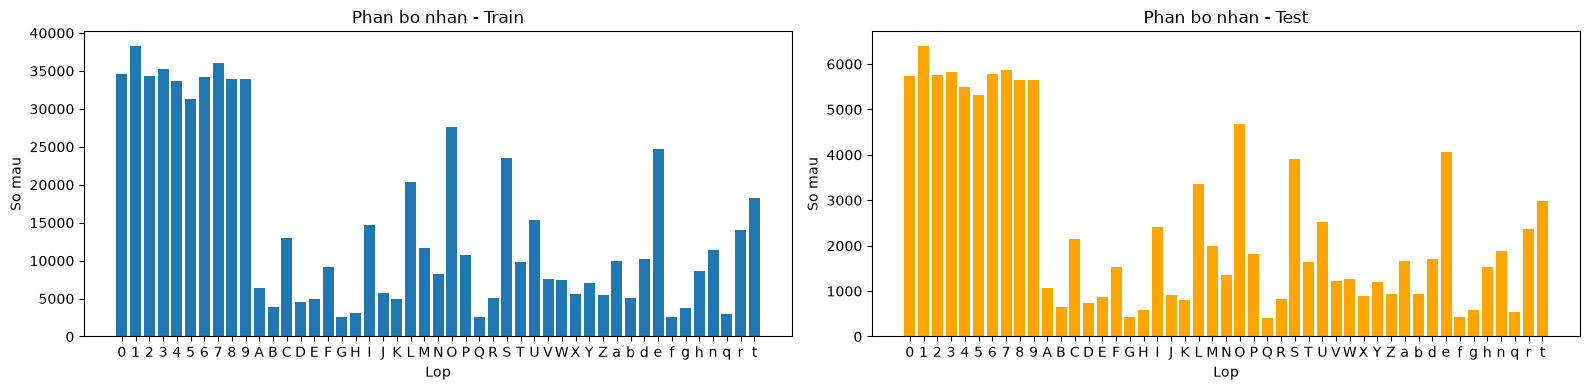

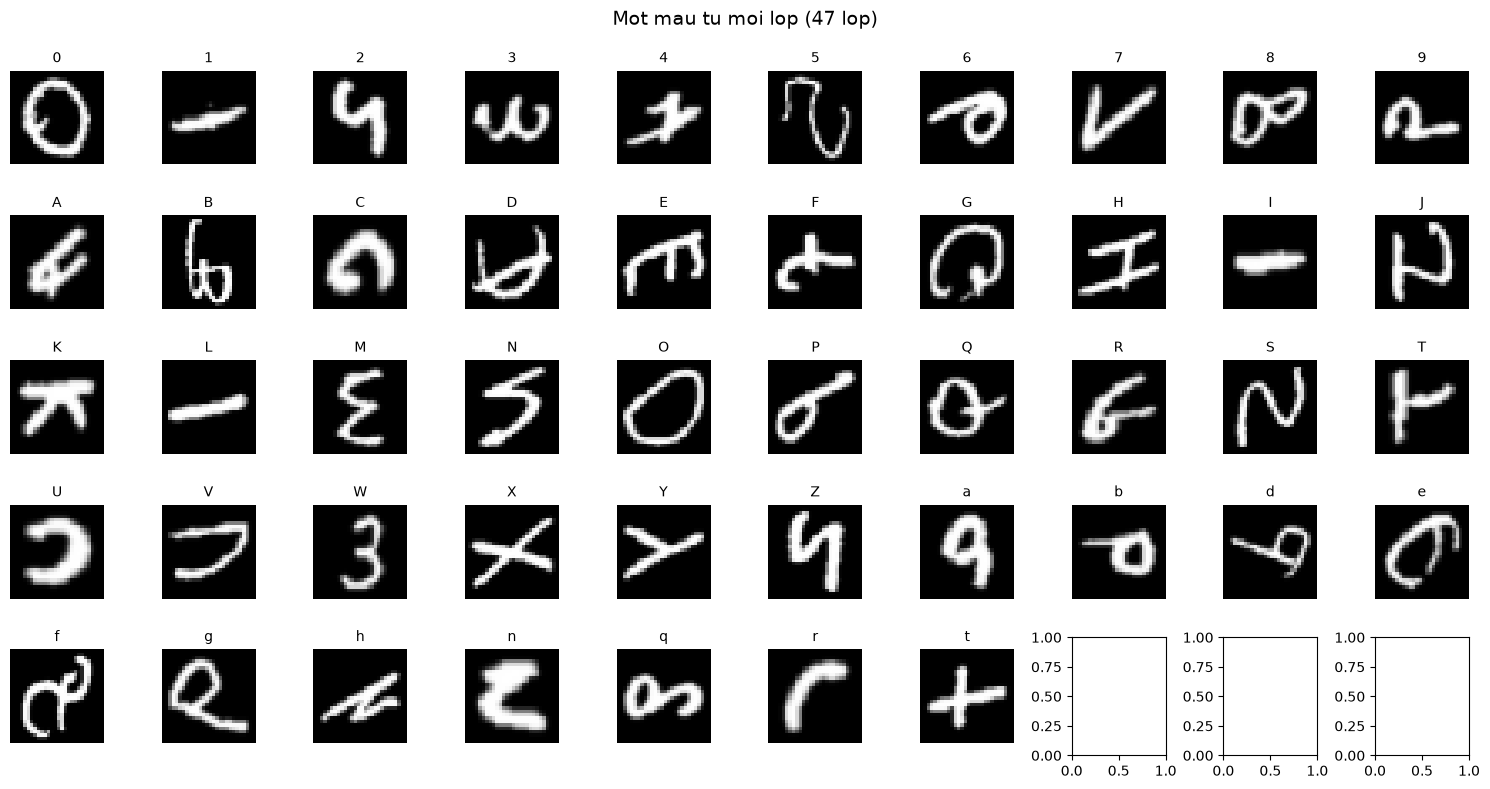

In [7]:
# ============================================================
# Phan tich so bo du lieu (Exploratory Data Analysis)
# ============================================================
import collections

print("=" * 60)
print("THONG TIN TONG QUAN VE DU LIEU")
print("=" * 60)
print(f"So mau train : {train_data.shape[0]:>8}")
print(f"So mau test  : {test_data.shape[0]:>8}")
print(f"So dac trung : {train_data.shape[1]} (= 28x28)")
print(f"So lop       : {len(label)}")
print(f"Kieu du lieu : {train_data.dtype}")
print(f"Gia tri pixel: min={train_data.min()}, max={train_data.max()}, mean={train_data.mean():.2f}, std={train_data.std():.2f}")

# Phan bo nhan
train_counts = collections.Counter(train_label)
test_counts  = collections.Counter(test_label)

print(f"\nPhan bo nhan train: min={min(train_counts.values())}, max={max(train_counts.values())}, mean={numpy.mean(list(train_counts.values())):.0f}")
print(f"Phan bo nhan test : min={min(test_counts.values())}, max={max(test_counts.values())}, mean={numpy.mean(list(test_counts.values())):.0f}")

# Bieu do phan bo nhan
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(range(47), [train_counts[i] for i in range(47)])
axes[0].set_title("Phan bo nhan - Train")
axes[0].set_xlabel("Lop")
axes[0].set_ylabel("So mau")
axes[0].set_xticks(range(47))
axes[0].set_xticklabels([label[i] for i in range(47)], rotation=0)

axes[1].bar(range(47), [test_counts[i] for i in range(47)], color="orange")
axes[1].set_title("Phan bo nhan - Test")
axes[1].set_xlabel("Lop")
axes[1].set_ylabel("So mau")
axes[1].set_xticks(range(47))
axes[1].set_xticklabels([label[i] for i in range(47)], rotation=0)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# Hien thi mot mau tu moi lop
fig, axes = plt.subplots(5, 10, figsize=(15, 8))
for cls in range(47):
    idx = numpy.where(train_label == cls)[0][0]
    row, col = cls // 10, cls % 10
    axes[row, col].imshow(train_data[idx].reshape(28, 28), cmap="gray")
    axes[row, col].set_title(label[cls], fontsize=10)
    axes[row, col].axis("off")
plt.suptitle("Mot mau tu moi lop (47 lop)", fontsize=14)
plt.tight_layout()
plt.savefig("sample_per_class.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
# Transform label
train_label = tf.keras.utils.to_categorical(train_label, 47)
test_label = tf.keras.utils.to_categorical(test_label, 47)

In [9]:
train_data = train_data.astype('float16')
test_data = test_data.astype('float16')

In [10]:
train_data /= 255
test_data /= 255

In [11]:
model = tf.keras.models.Sequential()

In [12]:
# model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(512, activation=tf.nn.relu, input_shape=(784,)))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Dense(512, activation=tf.nn.relu))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Dense(47, activation=tf.nn.softmax))

c:\Users\NC\anaconda3\envs\emnist\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
model.compile(optimizer=tf.optimizers.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])

In [14]:
model.fit(train_data, train_label, epochs=10, batch_size=256, validation_split=0.1)

Epoch 1/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.8173 - loss: 0.5714 - val_accuracy: 0.8702 - val_loss: 0.3720
Epoch 2/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.8628 - loss: 0.3980 - val_accuracy: 0.8772 - val_loss: 0.3485
Epoch 3/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8708 - loss: 0.3667 - val_accuracy: 0.8824 - val_loss: 0.3310
Epoch 4/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.8753 - loss: 0.3491 - val_accuracy: 0.8845 - val_loss: 0.3268
Epoch 5/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.8786 - loss: 0.3374 - val_accuracy: 0.8872 - val_loss: 0.3181
Epoch 6/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.8813 - loss: 0.3279 - val_accuracy: 0.8877 - val_loss: 0.3167
Epoch 7/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.8830 - loss: 0.3202 - val_accuracy: 0.8888 - val_loss: 0.3129
Epoch 8/10
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8841 - loss: 0

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


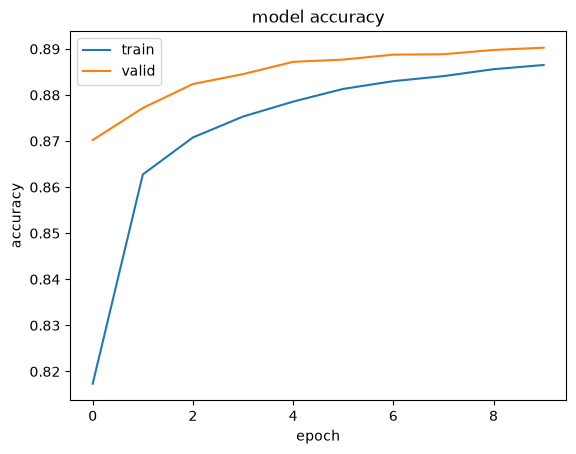

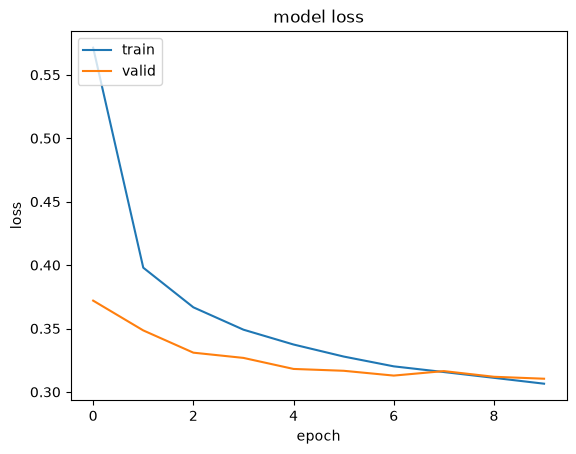

In [15]:
print(model.history.history.keys())
# summarize history for accuracy
plt.plot(model.history.history['accuracy'])
plt.plot(model.history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='upper left')
plt.savefig('acc_basic_mlp.png')

plt.show()
# summarize history for loss
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='upper left')
plt.savefig('loss_basic_mlp.png')
plt.show()

In [16]:
test_loss, test_acc = model.evaluate(test_data, test_label)

3636/3636 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8891 - loss: 0.3115


In [17]:
test_p = numpy.argmax(model.predict(test_data),axis=1)
test_l = numpy.argmax(test_label,axis=1)

3636/3636 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step


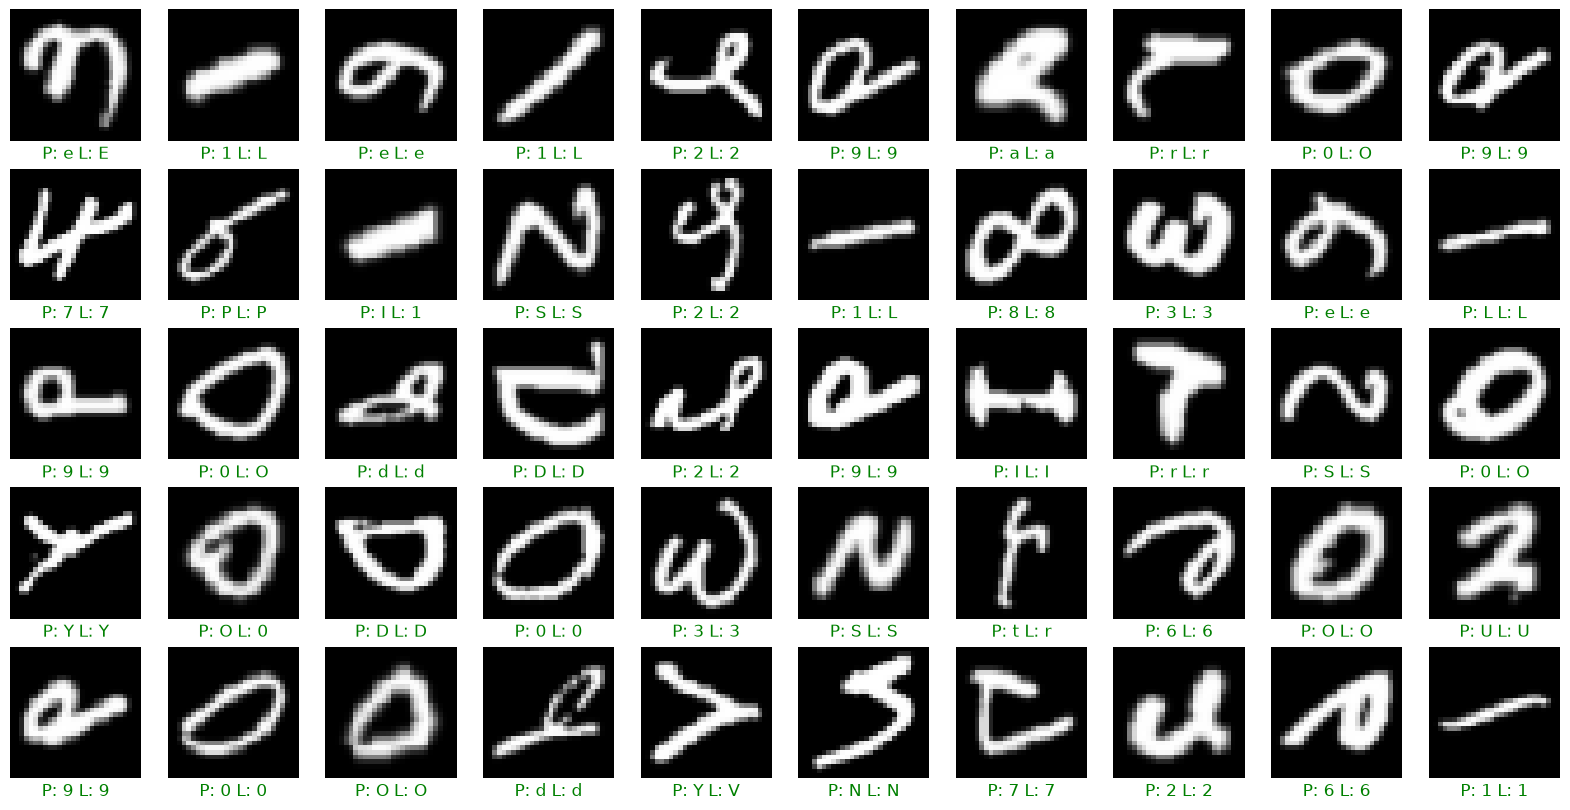

In [18]:
rows = 5 # defining no. of rows in figure
cols = 10 # defining no. of colums in figure

f = plt.figure(figsize=(2 * cols, 2 * rows)) # defining a figure 

test_data *= 255
test_data = test_data.astype('uint8')

for i in range(rows * cols): 
    f.add_subplot(rows, cols, i+1) # adding sub plot to figure on each iteration
    plt.imshow(test_data[i].reshape([28,28]),cmap="gray")
    plt.axis("off")
    plt.title(str('P: ' + label[test_p[i]]) + str(' L: ' + label[test_l[i]]) , y=-0.2,color="green")
    plt.savefig('result_mlp.png')

In [19]:
from sklearn import metrics
cm = metrics.confusion_matrix(test_l, test_p)

Confusion matrix, without normalization
[[4997    2    1 ...    0    0    1]
 [   0 5829    3 ...    0    4    7]
 [   1    2 5579 ...    0    2    1]
 ...
 [   1    2    2 ...  137    2    1]
 [   0    3    0 ...    0 2256    5]
 [   1    5    0 ...    0    3 2757]]
Normalized confusion matrix
[[8.70e-01 3.48e-04 1.74e-04 ... 0.00e+00 0.00e+00 1.74e-04]
 [0.00e+00 9.11e-01 4.69e-04 ... 0.00e+00 6.25e-04 1.09e-03]
 [1.73e-04 3.47e-04 9.68e-01 ... 0.00e+00 3.47e-04 1.73e-04]
 ...
 [1.88e-03 3.75e-03 3.75e-03 ... 2.57e-01 3.75e-03 1.88e-03]
 [0.00e+00 1.27e-03 0.00e+00 ... 0.00e+00 9.54e-01 2.11e-03]
 [3.36e-04 1.68e-03 0.00e+00 ... 0.00e+00 1.01e-03 9.25e-01]]


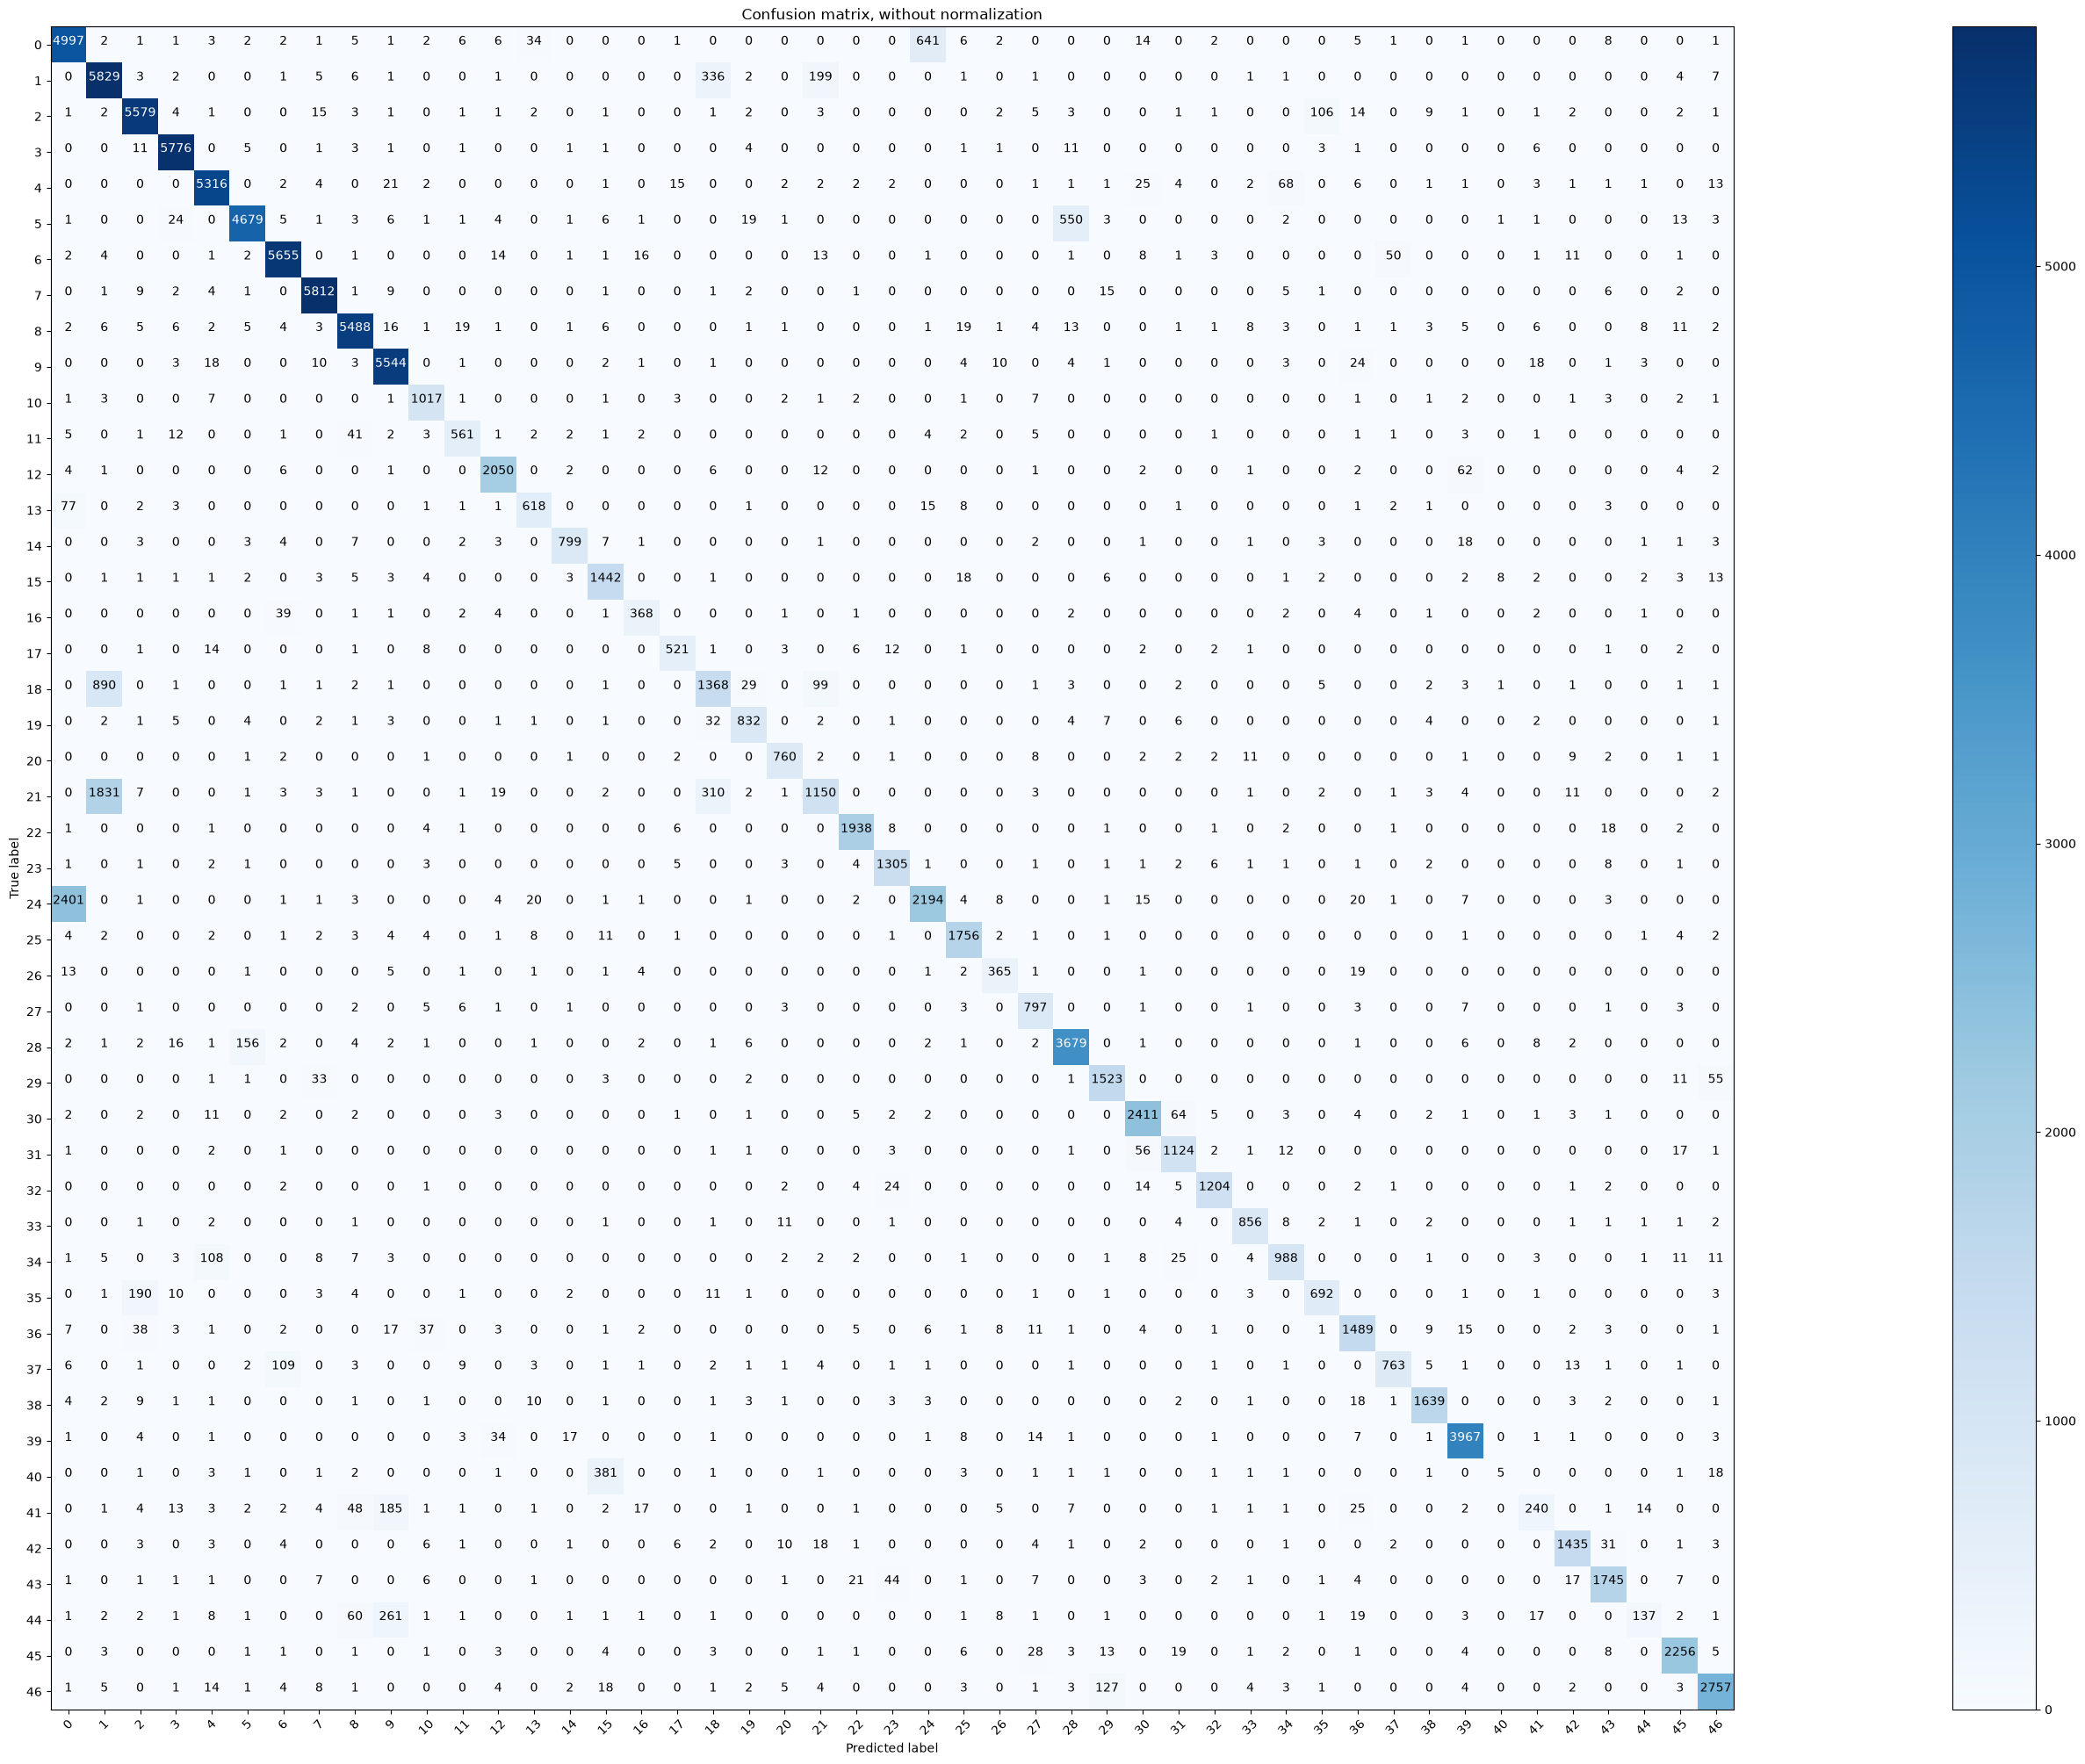

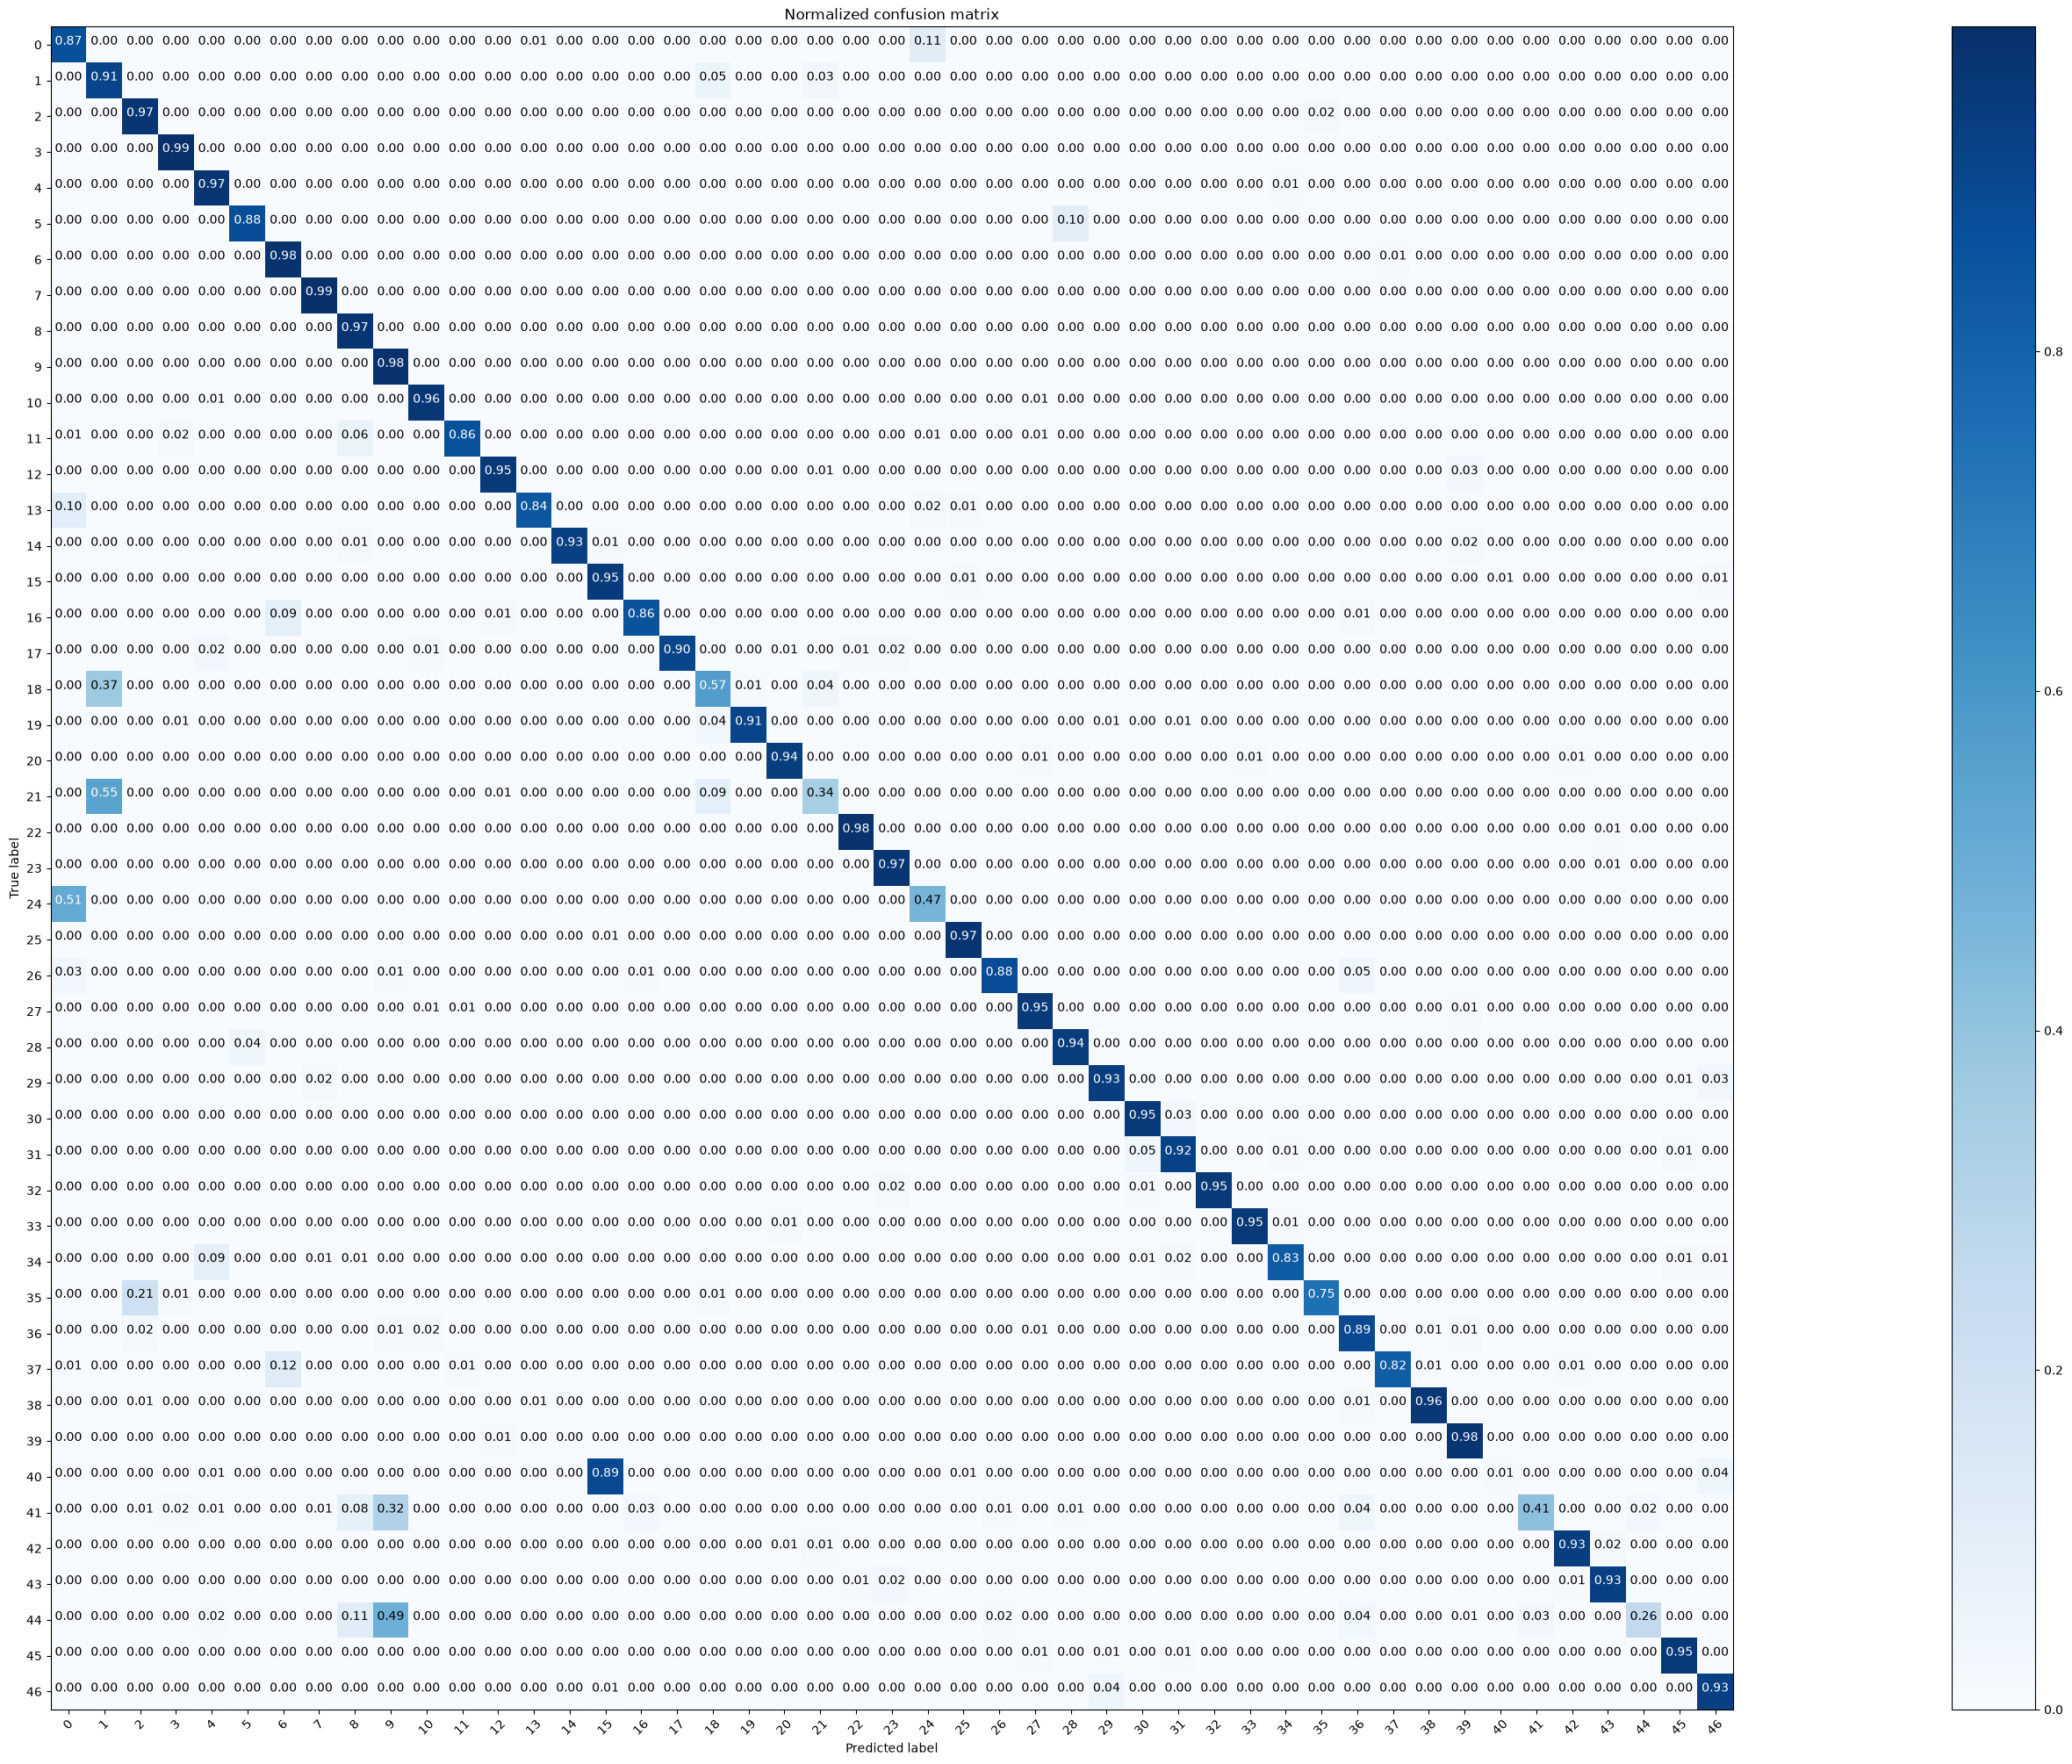

In [20]:
import itertools
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting normalize=True.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, numpy.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = numpy.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

class_names = [str(i) for i in range(47)]
numpy.set_printoptions(precision=2)

# Plot non-normalized confusion matrix
plt.figure(figsize=(50,20))
plot_confusion_matrix(cm, classes=class_names,
                      title='Confusion matrix, without normalization')

# Plot normalized confusion matrix
plt.figure(figsize=(50,20))
plot_confusion_matrix(cm, classes=class_names, normalize=True,
                      title='Normalized confusion matrix')
plt.savefig('confusion_matrix_mlp.png', dpi=120, bbox_inches='tight')
plt.show()

Do chinh xac theo lop:
   0 (lop  0): 0.8698  (5745 mau)
   1 (lop  1): 0.9108  (6400 mau)
   2 (lop  2): 0.9677  (5765 mau)
   3 (lop  3): 0.9912  (5827 mau)
   4 (lop  4): 0.9669  (5498 mau)
   5 (lop  5): 0.8785  (5326 mau)
   6 (lop  6): 0.9772  (5787 mau)
   7 (lop  7): 0.9896  (5873 mau)
   8 (lop  8): 0.9705  (5655 mau)
   9 (lop  9): 0.9811  (5651 mau)
   A (lop 10): 0.9612  (1058 mau)
   B (lop 11): 0.8604  (652 mau)
   C (lop 12): 0.9508  (2156 mau)
   D (lop 13): 0.8408  (735 mau)
   E (lop 14): 0.9291  (860 mau)
   F (lop 15): 0.9462  (1524 mau)
   G (lop 16): 0.8558  (430 mau)
   H (lop 17): 0.9045  (576 mau)
   I (lop 18): 0.5669  (2413 mau)
   J (lop 19): 0.9123  (912 mau)
   K (lop 20): 0.9394  (809 mau)
   L (lop 21): 0.3425  (3358 mau)
   M (lop 22): 0.9768  (1984 mau)
   N (lop 23): 0.9660  (1351 mau)
   O (lop 24): 0.4679  (4689 mau)
   P (lop 25): 0.9691  (1812 mau)
   Q (lop 26): 0.8795  (415 mau)
   R (lop 27): 0.9545  (835 mau)
   S (lop 28): 0.9436  (3899 mau)


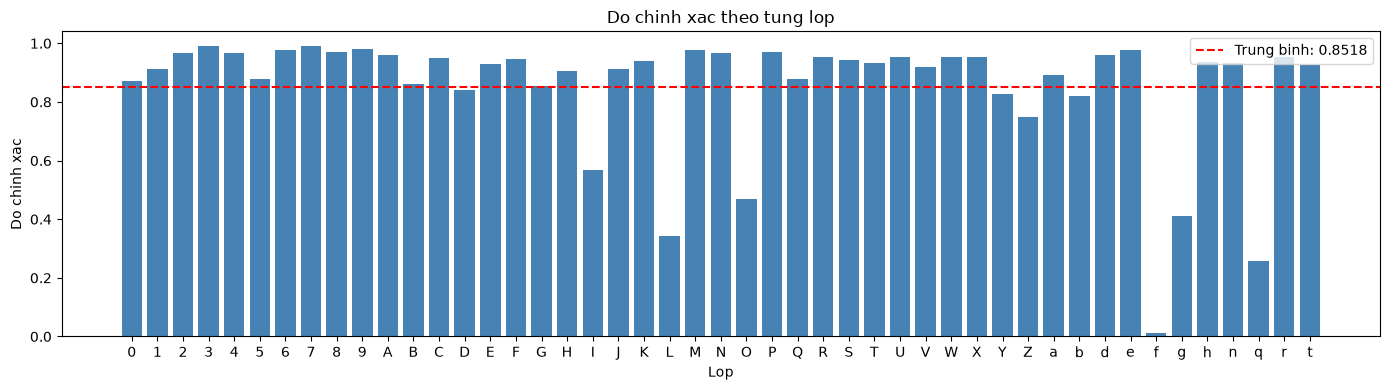

In [21]:
# ============================================================
# Phan tich loi chi tiet
# ============================================================

# Do chinh xac theo tung lop
per_class_acc = numpy.diag(cm) / cm.sum(axis=1)
print("Do chinh xac theo lop:")
for i in range(47):
    print(f"  {label[i]:>2s} (lop {i:2d}): {per_class_acc[i]:.4f}  ({int(cm.sum(axis=1)[i])} mau)")

print(f"\nDo chinh xac trung binh: {per_class_acc.mean():.4f}")
print(f"Lop tot nhat : {label[numpy.argmax(per_class_acc)]} ({per_class_acc.max():.4f})")
print(f"Lop te nhat  : {label[numpy.argmin(per_class_acc)]} ({per_class_acc.min():.4f})")

# Top 10 cap nham lan nhieu nhat
cm_copy = cm.copy()
numpy.fill_diagonal(cm_copy, 0)  # bo duong cheo
flat = cm_copy.flatten()
top_indices = flat.argsort()[-10:][::-1]

print("\nTop 10 cap nham lan nhieu nhat (thuc te -> du doan):")
for idx in top_indices:
    true_cls = idx // 47
    pred_cls = idx % 47
    print(f"  {label[true_cls]} -> {label[pred_cls]}: {cm_copy[true_cls, pred_cls]} mau")

# Bieu do do chinh xac theo lop
plt.figure(figsize=(14, 4))
plt.bar(range(47), per_class_acc, color="steelblue")
plt.axhline(y=per_class_acc.mean(), color="r", linestyle="--", label=f"Trung binh: {per_class_acc.mean():.4f}")
plt.xlabel("Lop")
plt.ylabel("Do chinh xac")
plt.title("Do chinh xac theo tung lop")
plt.xticks(range(47), [label[i] for i in range(47)], rotation=0)
plt.legend()
plt.tight_layout()
plt.savefig("per_class_accuracy.png", dpi=120, bbox_inches="tight")
plt.show()

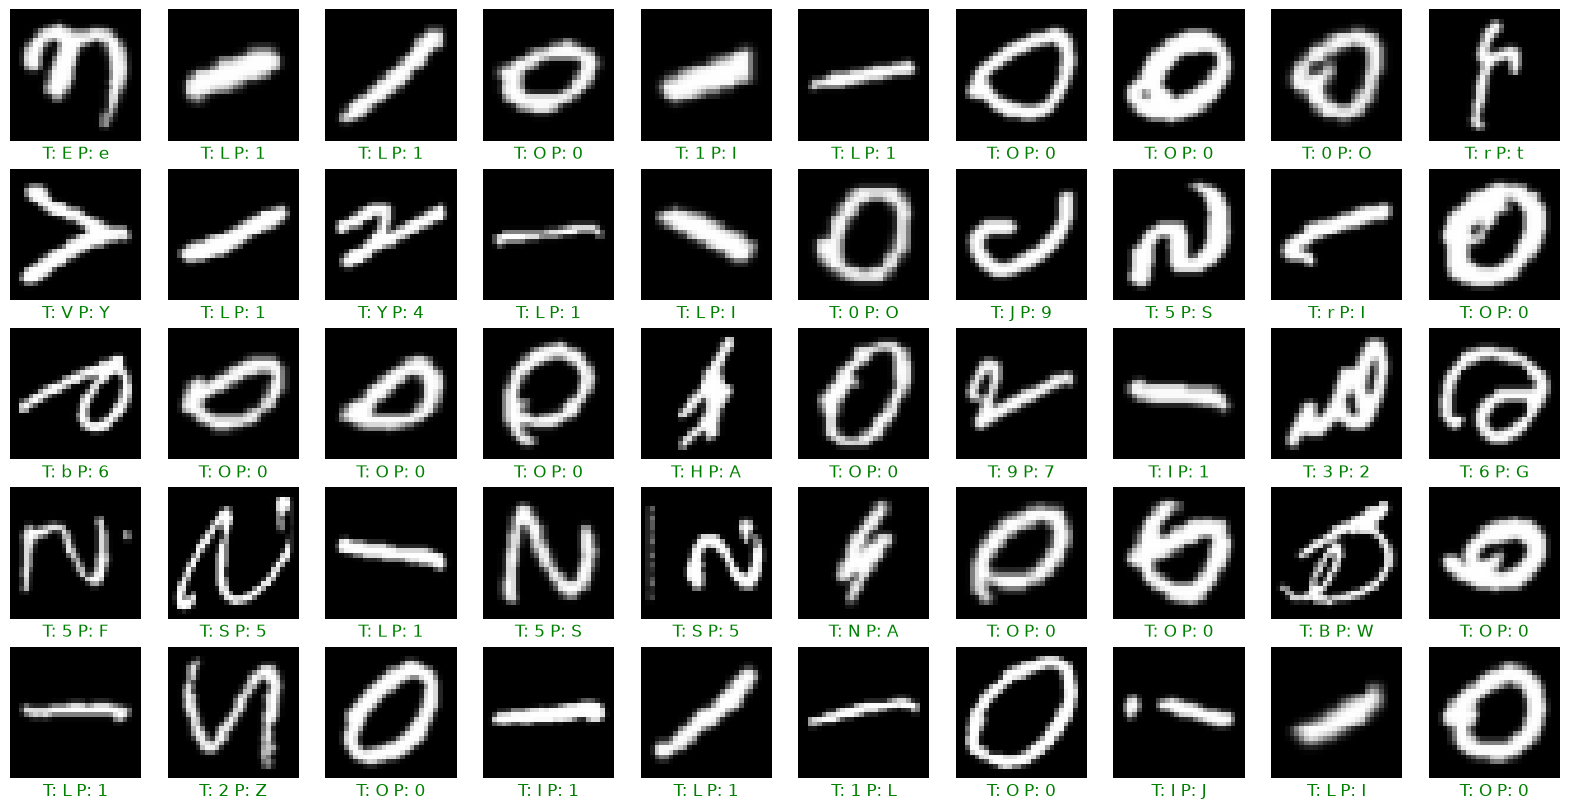

In [22]:
rows = 5
cols = 10
count = 50

f = plt.figure(figsize=(2*cols,2*rows))
sub_plot = 1
for i in range(test_data.shape[0]):
    if test_l[i]!=test_p[i] and count != 0:
        count -= 1
        f.add_subplot(rows,cols,sub_plot) 
        sub_plot+=1
        plt.imshow(test_data[i].reshape([28,28]),cmap="gray")
        plt.axis("off")
        plt.title("T: "+label[test_l[i]]+" P: "+label[test_p[i]], y=-0.2,color="Green")
plt.savefig("error_plots_mlp.png")
plt.show()

In [27]:
model.save('mlp_model.keras')

In [29]:
loaded = tf.keras.models.load_model(
    "mlp_model.keras",
    custom_objects={
        "relu": tf.nn.relu,
        "softmax_v2": tf.nn.softmax,
    },
)

In [30]:
test_loss, test_acc = loaded.evaluate(test_data, test_label)

3636/3636 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8863 - loss: 39.6999


In [31]:
test_loss, test_acc = model.evaluate(test_data, test_label)
print(f"Test accuracy: {test_acc:.4f}")

3636/3636 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8863 - loss: 39.6999
Test accuracy: 0.8863


## Han che va huong cai tien

### Han che cua giai phap hien tai

1. **Anh EMNIST ByMerge duoc luu o dang da xoay/flip.** Cac notebook hien **khong** ap dung `np.transpose`/`np.flip` de dua anh ve dung huong. Day la nguyen nhan chinh gay nham lan giua cac cap ky tu co hinh dang giong nhau khi xoay (O/0, Z/2, S/5, d/b, ...).
2. **Chua co data augmentation.** Voi tap du lieu lon nhieu bien the viet tay, cac phep augmentation (xoay nhe, dich chuyen, zoom) co the cai thien dang ke do chinh xac va giam overfitting.
3. **So epoch co dinh (10).** Khong dung early stopping hay learning rate scheduling - co the dung som khi val_loss khong cai thien.
4. **MLP bo qua cau truc khong gian.** MLP xem 784 pixel nhu vector phang, khong tan dung duoc tinh cuc bo cua anh - day la ly do CNN vuot troi hon.
5. **Mat can bang nhan nhe.** Mot so lop co it mau hon dang ke (xem bieu do phan bo) - co the dung class weighting de cai thien.

### Huong cai tien

- Ap dung `np.transpose` + `np.flip` trong cell tien xu ly de dua anh ve dung huong.
- Them data augmentation (rotation_range, width/height_shift, zoom).
- Dung `EarlyStopping` va `ReduceLROnPlateau` callback.
- Thu cac kien truc CNN sau hon (VGG-like, ResNet) hoac transfer learning.
- Can bang nhan bang `class_weight` trong `model.fit`.